# 분기 예정 공연 시작회차와 총매출액·고정 야간매출액

종로구·마포구 / 외식업 10종 / 2023~2025년 / 진단 후 수정한 탐색 분석

**12번 데이터셋 선행 실행이 필요하다.** 12번 완료 상태·검증 명세·입력 해시를 확인한 뒤 회귀한다. 실제 개최회차·관객·티켓 판매·실제 공연 종료 직후 매출을 관측한 분석이 아니다. 예정 시작회차는 현재 안내의 정상 요일 일정을 등록기간에 반복한 값이며, 휴연·취소·과거 일정 변경·공휴일 특별 일정은 확인되지 않았다.

주 결과는 총매출액, 보조 결과는 고정 21~24시 매출액의 `ln(1+원)`이다. 야간 매출비중과 금액 계수를 직접 비교하지 않는다. 네트워크 요청과 기존 파일 변경 없이 새 결과를 `results/main/revised_quarterly/13_*`에만 저장한다.

In [1]:
from pathlib import Path
import os
for key in ['OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','OMP_NUM_THREADS']: os.environ[key]='1'
import ast,json,hashlib,platform
from datetime import datetime,timezone
import numpy as np
import pandas as pd
from scipy import linalg,stats
from scipy.spatial.distance import cdist
from statsmodels.stats.multitest import multipletests
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'AGENTS.md').is_file() and (p/'data/raw').is_dir())
R=ROOT/'results/main/revised_quarterly'; PLAN_PATH=ROOT/'metadata/main/revised_quarterly_plan.json'
sha=lambda p:hashlib.sha256(p.read_bytes()).hexdigest()
read_json=lambda p:json.loads(p.read_text(encoding='utf-8'))
PLAN=read_json(PLAN_PATH); plan_sha=sha(PLAN_PATH)
assert PLAN['primary_availability_pct']==100 and PLAN['minimum_industry_clusters']==20
assert PLAN['area_industry_quarter_fixed_effect'] is False
assert [s['id'] for s in PLAN['scenarios']]==['primary_centroid100','centroid90','min_distance100','id_same_sample']
SOURCE05=ROOT/'notebooks/main/analysis/05_외식업_고정효과분석.ipynb'
protected={**PLAN['protected_source_sha256'],PLAN_PATH.relative_to(ROOT).as_posix():plan_sha,SOURCE05.relative_to(ROOT).as_posix():sha(SOURCE05)}
assert all(sha(ROOT/p)==v for p,v in protected.items())
KEY=['area_id','industry_id','quarter']; INDUSTRY_IDS=[f'CS100{i:03d}' for i in range(1,11)]
OUTCOMES={'log1p_total_sales_won':'분기 총매출액 ln(1+원)','log1p_night_sales_21_24_won':'21~24시 매출액 ln(1+원)'}
PRIMARY='primary_centroid100'
pd.set_option('display.max_rows',45); pd.set_option('display.float_format',lambda v:f'{v:,.6f}')
print('결과 전 고정 계획:',PLAN['frozen_before_revised_model_fitting'])

결과 전 고정 계획: 2026-10-05T06:29:53.532335+09:00


## 1. 고정한 질문과 계산 함수

업종별 상권·분기 FE를 제거한다. 상권×업종×분기 FE를 넣지 않으므로 분기 전반의 매출액 관련성을 묻는다. 중심점500m는 상권 전체 매출을 그 거리 안의 소비로 바꾸는 방법이 아니며, 매출을 면적으로 나누지 않는다.

총매출>0·야간매출≥0이 모두 관측된 공통 표본에서 실제 야간0을 유지한다. 상권×업종 최소2분기, 업종 최소20상권과 식별 가능한 잔차 노출 변동이 필요하다. 미충족은 미추정으로 남긴다. 20상권은 정밀도를 보장하지 않는다.

중심점100% 주모형, 중심점90%, 최단거리100%, 같은 중심점·같은 행의 ID 비교를 고정한다. 100%는 후보 ID가 일정 기준을 모두 통과했다는 뜻이며 실제 노출100% 관측이 아니다. 90%에서는 알려진 부분합을 쓴다. 각 사양의 결과별10 BH와 전체20 BH를 모두 보고하며, 미추정은 보정에서만 p=1이다. 전체20 BH를 주결론에 함께 사용한다.

In [2]:
found=[]
for cell in read_json(SOURCE05)['cells']:
    if cell['cell_type']!='code': continue
    source=''.join(cell['source'])
    if any(line.lstrip().startswith(('%','!')) for line in source.splitlines()): continue
    found.extend(node for node in ast.parse(source).body if isinstance(node,ast.FunctionDef) and node.name=='absorb_effects')
assert len(found)==1
exec(compile(ast.fix_missing_locations(ast.Module(body=found,type_ignores=[])),str(SOURCE05),'exec'))
def key_hash(f):
    return hashlib.sha256(f[KEY].sort_values(KEY).to_csv(index=False,lineterminator='\n').encode('utf-8')).hexdigest()
def fit_system(frame,outcome):
    blocks=[]; eligibility=[]
    for ind in INDUSTRY_IDS:
        f=frame.loc[frame.industry_id.eq(ind)].sort_values(KEY).reset_index(drop=True); g=f.area_id.nunique()
        row=dict(industry_id=ind,nobs=len(f),clusters=g,sample_key_sha256=key_hash(f))
        if g<PLAN['minimum_industry_clusters']:
            eligibility.append(dict(**row,status='too_few_clusters',residual_x_sd=np.nan,nuisance_rank=np.nan)); continue
        z,rank=absorb_effects(f,[outcome,'x']); y,x=z[:,0],z[:,1]; info=float(x@x)
        ok=info>1e-10 and float(x.std())>1e-10
        eligibility.append(dict(**row,status='estimated' if ok else 'no_identifiable_within_change',residual_x_sd=float(x.std()),nuisance_rank=rank))
        if ok: blocks.append(dict(industry_id=ind,frame=f,y=y,x=x,rank=rank,info=info))
    if not blocks: return dict(status='not_estimable',blocks=[],eligibility=eligibility,nobs=0,clusters=0,rank=0,beta=np.array([]),cov=np.empty((0,0)),area_ids=[],scores=np.empty((0,0)))
    areas=sorted(set().union(*(set(b['frame'].area_id) for b in blocks))); amap={a:i for i,a in enumerate(areas)}
    g=len(areas); n=sum(len(b['x']) for b in blocks); k=sum(b['rank']+1 for b in blocks)
    assert n>k and g>=20
    beta=np.array([float(b['x']@b['y'])/b['info'] for b in blocks]); bread=np.diag([1/b['info'] for b in blocks]); scores=np.zeros((g,len(blocks)))
    for j,b in enumerate(blocks):
        b['residual']=b['y']-b['x']*beta[j]
        np.add.at(scores[:,j],b['frame'].area_id.map(amap).to_numpy(),b['x']*b['residual'])
    correction=g/(g-1)*(n-1)/(n-k); cov=correction*bread@(scores.T@scores)@bread; cov=(cov+cov.T)/2
    assert np.isfinite(beta).all() and np.isfinite(cov).all() and np.diag(cov).min()>0
    return dict(status='estimated',blocks=blocks,eligibility=eligibility,nobs=n,clusters=g,rank=k,df=g-1,beta=beta,cov=cov,bread=bread,scores=scores,area_ids=areas,correction=correction)
def estimate_row(m,j):
    b=float(m['beta'][j]); se=float(np.sqrt(m['cov'][j,j])); crit=stats.t.ppf(.975,m['df'])
    return dict(coefficient=b,standard_error=se,ci_low=b-crit*se,ci_high=b+crit*se,p_value=float(2*stats.t.sf(abs(b/se),m['df'])))
def explicit_system_check(m,outcome,name):
    import statsmodels.api as sm
    from statsmodels.stats.sandwich_covariance import cov_cluster
    ds=[]; ys=[]; xs=[]; areas=[]
    for b in m['blocks']:
        f=b['frame']; dummy=np.column_stack([pd.get_dummies(f.area_id,dtype=float),pd.get_dummies(f.quarter,dtype=float)])
        _,_,piv=linalg.qr(dummy,mode='economic',pivoting=True)
        ds.append(dummy[:,piv[:b['rank']]]); ys.append(f[outcome].to_numpy()); xs.append(f.x.to_numpy()[:,None]); areas.extend(f.area_id)
    design=np.column_stack([linalg.block_diag(*ds),linalg.block_diag(*xs)]); y=np.concatenate(ys)
    exact=sm.OLS(y,design).fit(); covariance=cov_cluster(exact,np.asarray(areas),use_correction=True); k=len(m['blocks'])
    be=float(np.max(np.abs(exact.params[-k:]-m['beta']))); ve=float(np.max(np.abs(covariance[-k:,-k:]-m['cov'])))
    assert int(np.linalg.matrix_rank(design))==m['rank'] and be<1e-8 and ve<1e-8,(name,be,ve)
    return dict(check=name,passed=True,beta_max_error=be,cov_max_error=ve,nobs=len(y),design_rank=m['rank'])

### 입력 완료 전 구현 검증

불균형 합성 자료에서 명시적 더미 OLS와 계수·업종 간 교차항을 포함한 상권 군집 공분산을 비교한다. 원래 노트북의 함수 정의만 읽었으며 저장·전체실행 셀은 실행하지 않는다.

In [3]:
rng=np.random.default_rng(20261005)
toy=pd.MultiIndex.from_product([INDUSTRY_IDS[:2],[str(i) for i in range(24)],['q1','q2','q3','q4']],names=['industry_id','area_id','quarter']).to_frame(index=False)
toy=toy.loc[~(toy.area_id.isin(['1','4'])&toy.quarter.eq('q2'))].reset_index(drop=True)
toy['x']=rng.normal(size=len(toy)); toy['toy_y']=.3*toy.x+rng.normal(size=len(toy))
validation=[explicit_system_check(fit_system(toy,'toy_y'),'toy_y','synthetic_dummy_OLS_and_joint_cluster_covariance')]
display(pd.DataFrame(validation))

,check,passed,beta_max_error,cov_max_error,nobs,design_rank
0,synthetic_dummy_OLS_and_joint_cluster_covariance,True,0.000000,0.000000,188,56


## 2. 12번 완료 상태와 고정 입력

완료·검증·불변 플래그, 계획 SHA, 모든 12번 산출물 SHA를 먼저 확인한다. 기존18120키와 총매출·야간매출 값이 보존됐는지도 대조한다. 이후 12번 파일은 고정 입력으로만 읽는다.

In [4]:
summary_path=R/'12_dataset_summary.json'
assert summary_path.is_file(),'12번 데이터셋 완료 명세가 없습니다.'
s12=read_json(summary_path)
assert s12['status']=='complete' and s12['all_inputs_unchanged'] and s12['validation_all_passed']
assert s12['plan_sha256']==plan_sha
input_hashes={summary_path.relative_to(ROOT).as_posix():sha(summary_path)}
for path,record in s12['outputs'].items():
    assert sha(ROOT/path)==record['sha256'],path
    input_hashes[path]=record['sha256']
panel_path=ROOT/s12['panel_path']; assert sha(panel_path)==s12['panel_sha256']
panel=pd.read_csv(panel_path,dtype={k:str for k in KEY})
assert len(panel)==18120 and not panel.duplicated(KEY).any()
base=pd.read_csv(ROOT/'data/analysis/final/food_industry_panel.csv',dtype={k:str for k in KEY})
match=base[KEY+['total_sales','night_sales']].merge(panel[KEY+['total_sales','night_sales']],on=KEY,how='outer',validate='one_to_one',indicator=True,suffixes=('_original','_revised'))
assert match['_merge'].eq('both').all()
for col in ['total_sales','night_sales']: assert np.allclose(match[col+'_original'],match[col+'_revised'],equal_nan=True,rtol=0,atol=0)
INDUSTRIES=dict(panel[['industry_id','industry']].drop_duplicates().sort_values('industry_id').to_numpy()); assert list(INDUSTRIES)==INDUSTRY_IDS
for spatial in ['centroid500','min_distance500']:
    candidate=panel['candidate_id_count_'+spatial]; eligible=panel['eligible_id_count_'+spatial]
    assert candidate.notna().all() and eligible.notna().all() and eligible.le(candidate).all()
    expected=np.where(candidate.gt(0),100*eligible/candidate,100)
    assert np.allclose(panel['availability_pct_'+spatial],expected,rtol=0,atol=1e-8)
    assert panel['known_scheduled_start_count_'+spatial].ge(0).all()
assert panel.crs_epsg.eq(5181).all() and panel[['centroid_x_m','centroid_y_m']].notna().all().all()
panel['log1p_total_sales_won']=np.log1p(panel.total_sales.where(panel.total_sales.gt(0)))
panel['log1p_night_sales_21_24_won']=np.log1p(panel.night_sales.where(panel.night_sales.ge(0)))
common_observed=panel.total_sales.gt(0)&panel.night_sales.ge(0)&panel.total_sales.notna()&panel.night_sales.notna()
validation.append(dict(check='original_keys_and_sales_preserved',passed=True,beta_max_error=0,cov_max_error=0,nobs=len(panel)))
print('고정 패널:',len(panel),'행 / 공통 결과변수 관측:',int(common_observed.sum()))

고정 패널: 18120 행 / 공통 결과변수 관측: 7661


## 3. 사양별 표본·일정 가용률·야간 0원

가용률 적용 후 상권×업종2분기 조건을 적용하며 두 결과변수는 같은 행을 쓴다. ID 비교는 중심점100% 행을 복사한다. 야간0 비중과 인접 분기0↔양수 전환은 기술통계다. 이 전환도 포함한 log(1+원)은 양수 매출만의 성장률 모형이 아니며 화폐 단위에 의존할 수 있다.

In [5]:
frames={}; flow=[]
def flow_row(name,stage,f):
    return dict(scenario=name,stage=stage,nobs=len(f),areas=f.area_id.nunique(),area_quarters=len(f[['area_id','quarter']].drop_duplicates()),entities=len(f[['area_id','industry_id']].drop_duplicates()))
for s in PLAN['scenarios']:
    name=s['id']; spatial=s['spatial']
    if name=='id_same_sample':
        f=frames[PRIMARY].copy(); f['exposure_count']=f.candidate_id_count_centroid500; f['x']=np.log1p(f.exposure_count)
        assert key_hash(f)==key_hash(frames[PRIMARY]); flow.append(flow_row(name,'exact_primary_common_sample',f))
    else:
        f=panel.copy(); flow.append(flow_row(name,'full_keys',f))
        f=f.loc[common_observed].copy(); flow.append(flow_row(name,'common_outcomes_observed',f))
        f=f.loc[f['availability_pct_'+spatial].ge(s['availability_pct'])].copy(); flow.append(flow_row(name,'availability_passed',f))
        f['exposure_count']=f['known_scheduled_start_count_'+spatial]; assert f.exposure_count.notna().all()
        f['x']=np.log1p(f.exposure_count)
        count=f.groupby(['area_id','industry_id']).quarter.transform('nunique')
        f=f.loc[count.ge(PLAN['minimum_observations_per_area_industry'])].sort_values(KEY).reset_index(drop=True)
        flow.append(flow_row(name,'at_least_two_quarters',f))
    frames[name]=f
sample_flow=pd.DataFrame(flow); display(sample_flow)
zero_rows=[]; support_rows=[]; availability_rows=[]
for scenario,f in frames.items():
    spatial=next(s['spatial'] for s in PLAN['scenarios'] if s['id']==scenario)
    for ind in INDUSTRY_IDS:
        d=f.loc[f.industry_id.eq(ind)].copy().sort_values(['area_id','quarter'])
        d['_qindex']=d.quarter.str[:4].astype(int)*4+d.quarter.str[-1].astype(int)
        previous=d.groupby('area_id').night_sales.shift(); adjacent=d.groupby('area_id')._qindex.diff().eq(1)
        zero_rows.append(dict(scenario=scenario,industry_id=ind,industry=INDUSTRIES[ind],sample_stage='before_industry_estimability',nobs=len(d),clusters=d.area_id.nunique(),
          night_zero_rows=int(d.night_sales.eq(0).sum()),night_zero_pct=100*float(d.night_sales.eq(0).mean()) if len(d) else np.nan,
          adjacent_pairs=int(adjacent.sum()),zero_to_positive=int((adjacent&previous.eq(0)&d.night_sales.gt(0)).sum()),positive_to_zero=int((adjacent&previous.gt(0)&d.night_sales.eq(0)).sum())))
        availability_rows.append(dict(scenario=scenario,industry_id=ind,industry=INDUSTRIES[ind],nobs=len(d),median_id_availability_pct=float(d['availability_pct_'+spatial].median()),
          minimum_id_availability_pct=float(d['availability_pct_'+spatial].min()),zero_candidate_rows=int(d['candidate_id_count_'+spatial].eq(0).sum()),
          nonzero_exposure_rows=int(d.exposure_count.gt(0).sum()),median_exposure=float(d.exposure_count.median()),max_exposure=float(d.exposure_count.max())))
    aq=f.groupby(['area_id','quarter']).industry_id.nunique(); selected=aq.loc[aq.eq(10)].reset_index()[['area_id','quarter']]
    complete=f.merge(selected,on=['area_id','quarter'],validate='many_to_one')
    support_rows.append(dict(scenario=scenario,sample_stage='before_industry_estimability',all10_areas=complete.area_id.nunique(),all10_area_quarters=len(selected),all10_rows=len(complete),scenario_rows=len(f),all10_row_share_pct=100*len(complete)/len(f) if len(f) else np.nan))
zero_night=pd.DataFrame(zero_rows); common10=pd.DataFrame(support_rows); availability=pd.DataFrame(availability_rows)
display(zero_night.query("scenario == 'primary_centroid100'")); display(common10)

,scenario,stage,nobs,areas,area_quarters,entities
0,primary_centroid100,full_keys,18120,151,1812,1510
1,primary_centroid100,common_outcomes_observed,7661,135,1593,693
2,primary_centroid100,availability_passed,5042,118,1119,597
3,primary_centroid100,at_least_two_quarters,5015,114,1115,570
4,centroid90,full_keys,18120,151,1812,1510
5,centroid90,common_outcomes_observed,7661,135,1593,693
6,centroid90,availability_passed,6806,128,1422,665
7,centroid90,at_least_two_quarters,6791,127,1421,650
8,min_distance100,full_keys,18120,151,1812,1510
9,min_distance100,common_outcomes_observed,7661,135,1593,693


,scenario,industry_id,industry,sample_stage,nobs,clusters,night_zero_rows,night_zero_pct,adjacent_pairs,zero_to_positive,positive_to_zero
0,primary_centroid100,CS100001,한식음식점,before_industry_estimability,1021,106,38,3.721841,828,7,8
1,primary_centroid100,CS100002,중식음식점,before_industry_estimability,292,37,28,9.589041,226,7,6
2,primary_centroid100,CS100003,일식음식점,before_industry_estimability,282,35,41,14.539007,213,1,2
3,primary_centroid100,CS100004,양식음식점,before_industry_estimability,412,50,40,9.708738,312,10,12
4,primary_centroid100,CS100005,제과점,before_industry_estimability,330,40,37,11.212121,255,4,5
5,primary_centroid100,CS100006,패스트푸드점,before_industry_estimability,263,33,39,14.828897,201,8,8
6,primary_centroid100,CS100007,치킨전문점,before_industry_estimability,309,37,0,0.000000,241,0,0
7,primary_centroid100,CS100008,분식전문점,before_industry_estimability,575,64,117,20.347826,459,16,14
8,primary_centroid100,CS100009,호프-간이주점,before_industry_estimability,649,71,1,0.154083,524,0,1
9,primary_centroid100,CS100010,커피-음료,before_industry_estimability,882,97,235,26.643991,701,28,33


,scenario,sample_stage,all10_areas,all10_area_quarters,all10_rows,scenario_rows,all10_row_share_pct
0,primary_centroid100,before_industry_estimability,13,90,900,5015,17.946162
1,centroid90,before_industry_estimability,16,148,1480,6791,21.793550
2,min_distance100,before_industry_estimability,7,40,400,3537,11.309019
3,id_same_sample,before_industry_estimability,13,90,900,5015,17.946162


## 4. 네 사양의 고정효과 회귀

업종별 상권·분기 FE를 FWL로 제거한다. 상권별 score에 그 상권의 모든 업종·분기 기여를 합산하며 CR1=`G/(G−1)×(N−1)/(N−K)`이다. K에는 흡수 FE 순위와 모든 기울기를 포함하고 개별 추론은 t(G−1)이다. 상권 간 공간 의존은 별도 감도로 다룬다. 최소군집 기준을 낮추거나 유의 사양을 선택하지 않는다.

In [6]:
models={}; effect_rows=[]; eligibility_rows=[]; samples=[]; membership=[]; information_rows=[]; cov_rows=[]
for scenario,frame in frames.items():
    for outcome in OUTCOMES:
        m=fit_system(frame,outcome); models[(scenario,outcome)]=m
        eligibility_rows.extend(dict(scenario=scenario,outcome=outcome,industry=INDUSTRIES[e['industry_id']],**e) for e in m['eligibility'])
        estimated=pd.concat([b['frame'] for b in m['blocks']],ignore_index=True) if m['blocks'] else frame.iloc[:0]
        samples.append(dict(scenario=scenario,outcome=outcome,status=m['status'],nobs_common_preeligibility=len(frame),nobs_estimated=m['nobs'],clusters_estimated=m['clusters'],
          estimated_industries=len(m['blocks']),design_rank=m['rank'],inference_df=m.get('df',np.nan),cluster_correction=m.get('correction',np.nan),
          common_sample_key_sha256=key_hash(frame),estimated_sample_key_sha256=key_hash(estimated)))
        for b in m['blocks']: membership.append(b['frame'][KEY].assign(scenario=scenario,outcome=outcome))
        positions={b['industry_id']:j for j,b in enumerate(m['blocks'])}
        for ind in INDUSTRY_IDS:
            e=next(x for x in m['eligibility'] if x['industry_id']==ind)
            row=dict(scenario=scenario,outcome=outcome,industry_id=ind,industry=INDUSTRIES[ind],status=e['status'],nobs_industry=e['nobs'],clusters_industry=e['clusters'],nobs_total=m['nobs'],clusters_total=m['clusters'],
                     coefficient=np.nan,standard_error=np.nan,ci_low=np.nan,ci_high=np.nan,p_value=np.nan)
            if ind in positions:
                j=positions[ind]; b=m['blocks'][j]; row.update(estimate_row(m,j))
                info=pd.Series(b['x']**2,index=b['frame'].area_id).groupby(level=0).sum(); shares=(info/info.sum()).sort_values(ascending=False)
                raw=b['frame'].x.to_numpy(); rawss=float(np.sum((raw-raw.mean())**2)); ranges=b['frame'].groupby('area_id').x.agg(['min','max'])
                information_rows.append(dict(scenario=scenario,outcome=outcome,industry_id=ind,industry=INDUSTRIES[ind],clusters=len(info),
                  raw_temporally_changing_clusters=int((ranges['max']-ranges['min']).gt(1e-10).sum()),residual_x_sd=float(b['x'].std()),raw_centered_x_ss=rawss,residual_x_ss=b['info'],
                  fe_variance_retained_pct=100*b['info']/rawss,top1_information_share=float(shares.iloc[0]),top5_information_share=float(shares.head(5).sum()),
                  inverse_herfindahl_information=float(1/(shares**2).sum()),clusters_spanning_log2=int((ranges['max']-ranges['min']).ge(np.log(2)).sum())))
            effect_rows.append(row)
        for i,a in enumerate(m['blocks']):
            for j,b in enumerate(m['blocks']): cov_rows.append(dict(scenario=scenario,outcome=outcome,industry_id_a=a['industry_id'],industry_id_b=b['industry_id'],covariance=float(m['cov'][i,j])))
effects=pd.DataFrame(effect_rows); eligibility=pd.DataFrame(eligibility_rows); model_samples=pd.DataFrame(samples)
information=pd.DataFrame(information_rows); covariance_table=pd.DataFrame(cov_rows)
member=pd.concat(membership,ignore_index=True) if membership else pd.DataFrame(columns=KEY+['scenario','outcome'])
assert len(effects)==80 and not member.duplicated(['scenario','outcome']+KEY).any()
effects['p_bh10']=np.nan; effects['p_bh20']=np.nan
for scenario in frames:
    ix=effects.scenario.eq(scenario); effects.loc[ix,'p_bh20']=multipletests(effects.loc[ix,'p_value'].fillna(1),method='fdr_bh')[1]
    for outcome in OUTCOMES:
        iy=ix&effects.outcome.eq(outcome); effects.loc[iy,'p_bh10']=multipletests(effects.loc[iy,'p_value'].fillna(1),method='fdr_bh')[1]
effects.loc[effects.status.ne('estimated'),['p_bh10','p_bh20']]=np.nan
for old,new in [('coefficient','doubling_pct'),('ci_low','doubling_ci_low'),('ci_high','doubling_ci_high')]: effects[new]=100*np.expm1(effects[old]*np.log(2))
effects['exposure_doubling_definition']='(1+exposure) doubles; delta log=ln2'
effects['transformed_outcome_unit']='conditional geometric mean of (sales_won+1), relative difference percent'
display(model_samples[['scenario','outcome','nobs_estimated','clusters_estimated','estimated_industries']])
display(effects.loc[effects.scenario.eq(PRIMARY),['outcome','industry','status','coefficient','standard_error','ci_low','ci_high','p_value','p_bh10','p_bh20']])

,scenario,outcome,nobs_estimated,clusters_estimated,estimated_industries
0,primary_centroid100,log1p_total_sales_won,5015,114,10
1,primary_centroid100,log1p_night_sales_21_24_won,5015,114,10
2,centroid90,log1p_total_sales_won,6791,127,10
3,centroid90,log1p_night_sales_21_24_won,6791,127,10
4,min_distance100,log1p_total_sales_won,3537,95,10
5,min_distance100,log1p_night_sales_21_24_won,3537,95,10
6,id_same_sample,log1p_total_sales_won,5015,114,10
7,id_same_sample,log1p_night_sales_21_24_won,5015,114,10


,outcome,industry,status,coefficient,standard_error,ci_low,ci_high,p_value,p_bh10,p_bh20
0,log1p_total_sales_won,한식음식점,estimated,0.004609,0.020913,-0.036823,0.046041,0.825954,0.938712,0.988118
1,log1p_total_sales_won,중식음식점,estimated,-0.004166,0.013749,-0.031406,0.023074,0.762434,0.938712,0.988118
2,log1p_total_sales_won,일식음식점,estimated,0.002689,0.034898,-0.066450,0.071828,0.938712,0.938712,0.988118
3,log1p_total_sales_won,양식음식점,estimated,0.005455,0.033205,-0.060329,0.071239,0.869803,0.938712,0.988118
4,log1p_total_sales_won,제과점,estimated,0.010157,0.026286,-0.041920,0.062234,0.699924,0.938712,0.988118
5,log1p_total_sales_won,패스트푸드점,estimated,0.072808,0.063555,-0.053107,0.198722,0.254389,0.938712,0.988118
6,log1p_total_sales_won,치킨전문점,estimated,-0.083685,0.054986,-0.192623,0.025253,0.130822,0.938712,0.988118
7,log1p_total_sales_won,분식전문점,estimated,0.025232,0.028941,-0.032105,0.082569,0.385135,0.938712,0.988118
8,log1p_total_sales_won,호프-간이주점,estimated,-0.010056,0.026835,-0.063222,0.043109,0.708556,0.938712,0.988118
9,log1p_total_sales_won,커피-음료,estimated,-0.015126,0.034804,-0.084079,0.053826,0.664667,0.938712,0.988118


### 실제 주표본 축소 자료의 명시적 더미 검증

추정 가능한 앞 두 업종에서 상권 ID 순서로 최대24개를 선택해 명시적 OLS·상권 군집 공분산과 비교한다. p값으로 선택하지 않으며 이 축소 표본 결과는 구현 검증에만 쓴다.

In [7]:
for outcome in OUTCOMES:
    parts=[]
    for b in models[(PRIMARY,outcome)]['blocks'][:2]:
        ids=sorted(b['frame'].area_id.unique())[:24]; parts.append(b['frame'].loc[b['frame'].area_id.isin(ids)])
    if parts:
        small=fit_system(pd.concat(parts,ignore_index=True),outcome); assert small['status']=='estimated'
        validation.append(explicit_system_check(small,outcome,'actual_reduced_dummy_OLS_'+outcome))
    else: validation.append(dict(check='actual_reduced_dummy_OLS_'+outcome,passed=False,reason='no_estimable_primary_industry'))
display(pd.DataFrame(validation))

,check,passed,beta_max_error,cov_max_error,nobs,design_rank
0,synthetic_dummy_OLS_and_joint_cluster_covariance,True,0.000000,0.000000,188,56.000000
1,original_keys_and_sales_preserved,True,0.000000,0.000000,18120,NaN
2,actual_reduced_dummy_OLS_log1p_total_sales_won,True,0.000000,0.000000,438,72.000000
3,actual_reduced_dummy_OLS_log1p_night_sales_21_...,True,0.000000,0.000000,438,72.000000


## 5. 예정회차와 ID: 같은 공간·같은 행

노출 단위가 다르므로 β 크기를 직접 비교해 지표의 효과를 평가하지 않는다. `(1+예정회차)`2배와 `(1+ID 수)`2배는 같은 관객 증가량이 아니다. 표본 해시·추정 가능 업종을 먼저 확인하고 효과 예시와 불확실성을 함께 읽는다. 과거 폴리곤 ID 총매출 결과는 다른 공간·표본의 기준선으로만 보존하며 과거 야간 비중은 비교표에 넣지 않는다.

In [8]:
comparison_rows=[]
for outcome in OUTCOMES:
    p=models[(PRIMARY,outcome)]; i=models[('id_same_sample',outcome)]
    pe=pd.concat([b['frame'][KEY] for b in p['blocks']],ignore_index=True) if p['blocks'] else frames[PRIMARY].iloc[:0]
    ie=pd.concat([b['frame'][KEY] for b in i['blocks']],ignore_index=True) if i['blocks'] else frames['id_same_sample'].iloc[:0]
    same_est=key_hash(pe)==key_hash(ie); assert key_hash(frames[PRIMARY])==key_hash(frames['id_same_sample'])
    for ind in INDUSTRY_IDS:
        ph=key_hash(frames[PRIMARY].loc[frames[PRIMARY].industry_id.eq(ind)]); ih=key_hash(frames['id_same_sample'].loc[frames['id_same_sample'].industry_id.eq(ind)]); assert ph==ih
        row=dict(outcome=outcome,industry_id=ind,industry=INDUSTRIES[ind],scheduled_sample_key_sha256=ph,id_sample_key_sha256=ih,
                 identical_candidate_rows=True,identical_entire_estimated_sample=same_est)
        for scenario,prefix in [(PRIMARY,'scheduled'),('id_same_sample','id')]:
            e=effects.loc[effects.scenario.eq(scenario)&effects.outcome.eq(outcome)&effects.industry_id.eq(ind)].iloc[0]
            row.update({prefix+'_'+name:e[name] for name in ['status','coefficient','standard_error','doubling_pct','doubling_ci_low','doubling_ci_high','p_bh20']})
        comparison_rows.append(row)
comparison=pd.DataFrame(comparison_rows); assert comparison.identical_candidate_rows.all()
if not comparison.identical_entire_estimated_sample.all():
    display(Markdown('**주의:** 두 지표의 식별 가능 업종이 달라 적합 표본 전체는 같지 않다. 미추정을 유지하며 완전히 같은 적합 표본의 비교라고 결론내리지 않는다.'))
for scenario in frames:
    h=model_samples.loc[model_samples.scenario.eq(scenario)]; assert h.common_sample_key_sha256.nunique()==1 and h.estimated_sample_key_sha256.nunique()==1
prior=pd.read_csv(ROOT/'results/main/baseline/09_industry_effects.csv').query("scenario == 'main_500' and outcome == 'log_sales'").copy()
prior['comparison_role']='historical reference only; original polygon distance and original sample'; prior['new_night_amount_comparable']=False
display(comparison[['outcome','industry','scheduled_status','id_status','identical_candidate_rows','identical_entire_estimated_sample','scheduled_doubling_pct','id_doubling_pct']])

,outcome,industry,scheduled_status,id_status,identical_candidate_rows,identical_entire_estimated_sample,scheduled_doubling_pct,id_doubling_pct
0,log1p_total_sales_won,한식음식점,estimated,estimated,True,True,0.320003,-0.741150
1,log1p_total_sales_won,중식음식점,estimated,estimated,True,True,-0.288367,-0.919467
2,log1p_total_sales_won,일식음식점,estimated,estimated,True,True,0.186578,5.332447
3,log1p_total_sales_won,양식음식점,estimated,estimated,True,True,0.378819,4.140419
4,log1p_total_sales_won,제과점,estimated,estimated,True,True,0.706506,0.466360
5,log1p_total_sales_won,패스트푸드점,estimated,estimated,True,True,5.176162,8.051869
6,log1p_total_sales_won,치킨전문점,estimated,estimated,True,True,-5.635572,-7.154288
7,log1p_total_sales_won,분식전문점,estimated,estimated,True,True,1.764341,-0.328531
8,log1p_total_sales_won,호프-간이주점,estimated,estimated,True,True,-0.694622,0.043306
9,log1p_total_sales_won,커피-음료,estimated,estimated,True,True,-1.043011,-0.705874


## 6. 주모형의 공간 표준오차 감도

β와 표본을 바꾸지 않는다. 상권별 모든 업종·분기 score를 합산해 `CR1×B×S′KS×B`를 계산한다. `K_ab=exp[-(중심점거리/1000m)²]`이며 EPSG:5181 미터 좌표를 사용한다. 같은상권 K=1로 시간 내 의존을 유지하고 인근상권 간 전시점 교차항을 포함한다. 중심점500m 노출을 공유하는 두 상권 중심점 간 거리는 최대1km일 수 있다는 공간 설계에 따라 대역폭을 결과 전에 고정했다.

정규근사95% 참고구간만 보고하며 공간 p값을 만들거나 주 t 검정을 대체하지 않는다. 두 밀집지역·유한상권에서 공간 의존 해결을 보장하지 않는다. 공간 SE는 반드시 커지지 않으며 큰 값만 선택하지 않는다. K=I의 기존 군집 공분산 재현·대칭·양의 준정부호를 검증한다.

In [9]:
spatial_rows=[]; kernel_checks=[]
coords=panel[['area_id','centroid_x_m','centroid_y_m']].drop_duplicates(); assert not coords.area_id.duplicated().any(); coords=coords.set_index('area_id')
for outcome in OUTCOMES:
    m=models[(PRIMARY,outcome)]
    if m['status']!='estimated': continue
    xy=coords.loc[m['area_ids'],['centroid_x_m','centroid_y_m']].to_numpy()
    distance=cdist(xy,xy); kernel=np.exp(-(distance/PLAN['spatial_se_sensitivity']['bandwidth_m'])**2)
    spatial=m['correction']*m['bread']@(m['scores'].T@kernel@m['scores'])@m['bread']; spatial=(spatial+spatial.T)/2
    identity=m['correction']*m['bread']@(m['scores'].T@np.eye(m['clusters'])@m['scores'])@m['bread']
    err=float(np.max(np.abs(identity-m['cov']))); km=float(np.linalg.eigvalsh(kernel).min()); vm=float(np.linalg.eigvalsh(spatial).min())
    assert np.max(np.abs(kernel-kernel.T))<1e-12 and np.allclose(np.diag(kernel),1)
    assert km>=-1e-9 and vm>=-1e-10 and np.diag(spatial).min()>0 and err<1e-10
    kernel_checks.append(dict(check='spatial_kernel_'+outcome,passed=True,identity_covariance_max_error=err,kernel_min_eigenvalue=km,covariance_min_eigenvalue=vm,clusters=m['clusters']))
    for j,b in enumerate(m['blocks']):
        beta=float(m['beta'][j]); se=float(np.sqrt(spatial[j,j])); base_se=float(np.sqrt(m['cov'][j,j])); crit=stats.norm.ppf(.975); low=beta-crit*se; high=beta+crit*se
        spatial_rows.append(dict(scenario=PRIMARY,outcome=outcome,industry_id=b['industry_id'],industry=INDUSTRIES[b['industry_id']],coefficient=beta,
          cluster_standard_error=base_se,spatial_standard_error=se,spatial_to_cluster_se_ratio=se/base_se,spatial_normal_ci_low=low,spatial_normal_ci_high=high,
          doubling_pct=100*np.expm1(beta*np.log(2)),doubling_spatial_ci_low=100*np.expm1(low*np.log(2)),doubling_spatial_ci_high=100*np.expm1(high*np.log(2)),
          kernel_bandwidth_m=1000,reference_interval='normal approximation 95%; no spatial p-value'))
spatial_sensitivity=pd.DataFrame(spatial_rows); validation.extend(kernel_checks)
assert all('p_value' not in column for column in spatial_sensitivity.columns)
display(spatial_sensitivity[['outcome','industry','cluster_standard_error','spatial_standard_error','spatial_to_cluster_se_ratio','doubling_spatial_ci_low','doubling_spatial_ci_high']])

,outcome,industry,cluster_standard_error,spatial_standard_error,spatial_to_cluster_se_ratio,doubling_spatial_ci_low,doubling_spatial_ci_high
0,log1p_total_sales_won,한식음식점,0.020913,0.021149,1.011308,-2.521407,3.244237
1,log1p_total_sales_won,중식음식점,0.013749,0.014059,1.022517,-2.174746,1.634389
2,log1p_total_sales_won,일식음식점,0.034898,0.034928,1.000869,-4.456402,5.055185
3,log1p_total_sales_won,양식음식점,0.033205,0.033929,1.021813,-4.143007,5.113951
4,log1p_total_sales_won,제과점,0.026286,0.021450,0.816045,-2.185849,3.684388
5,log1p_total_sales_won,패스트푸드점,0.063555,0.055635,0.875371,-2.480268,13.433710
6,log1p_total_sales_won,치킨전문점,0.054986,0.051777,0.941636,-12.045234,1.241190
7,log1p_total_sales_won,분식전문점,0.028941,0.027905,0.964228,-2.021403,5.696360
8,log1p_total_sales_won,호프-간이주점,0.026835,0.023796,0.886736,-3.853594,2.568140
9,log1p_total_sales_won,커피-음료,0.034804,0.036510,1.049032,-5.831636,3.989123


## 7. 효과 크기와 전체20 보정을 함께 읽기

`(1+노출)`2배는 β×ln2를 지수변환한 **(매출+1)의 조건부 기하평균 상대차이**다. 노출 자체의 정확한2배·원화 산술평균 매출 증가율·관람객의 인과효과가 아니다. 개별95% CI는 다중비교 동시 구간이 아니다. 동일상권 관측범위가 예시를 뒷받침하는지 정보표의 범위 지표도 읽는다.

수정은 기존 결과와 진단을 본 뒤 고정한 탐색 분석이다. 유의 결과가 생겨도 새기간 재현 전 확증적 발견으로 단정하지 않는다. 미추정과 비유의를 포함해 네 사양을 모두 제시한다.

In [10]:
primary=effects.loc[effects.scenario.eq(PRIMARY)].copy()
display(primary[['outcome','industry','status','doubling_pct','doubling_ci_low','doubling_ci_high','p_value','p_bh10','p_bh20','nobs_industry','clusters_industry']])
counts=effects.groupby(['scenario','outcome']).agg(planned_tests=('industry_id','size'),estimated=('status',lambda s:int(s.eq('estimated').sum())),
 raw_significant=('p_value',lambda s:int(s.lt(.05).sum())),bh10_significant=('p_bh10',lambda s:int(s.lt(.05).sum())),bh20_significant=('p_bh20',lambda s:int(s.lt(.05).sum()))).reset_index()
display(counts)
display(information.loc[information.scenario.eq(PRIMARY)&information.outcome.eq(PLAN['primary_outcome'])])
for scenario in frames:
    m=models[(scenario,PLAN['primary_outcome'])]; f=pd.concat([b['frame'] for b in m['blocks']],ignore_index=True) if m['blocks'] else frames[scenario].iloc[:0]
    aq=f.groupby(['area_id','quarter']).industry_id.nunique(); selected=aq.loc[aq.eq(10)].reset_index()[['area_id','quarter']]
    complete=f.merge(selected,on=['area_id','quarter'],validate='many_to_one')
    support_rows.append(dict(scenario=scenario,sample_stage='estimated_industries_only',all10_areas=complete.area_id.nunique(),all10_area_quarters=len(selected),
      all10_rows=len(complete),scenario_rows=len(f),all10_row_share_pct=100*len(complete)/len(f) if len(f) else np.nan))
common10=pd.DataFrame(support_rows)

,outcome,industry,status,doubling_pct,doubling_ci_low,doubling_ci_high,p_value,p_bh10,p_bh20,nobs_industry,clusters_industry
0,log1p_total_sales_won,한식음식점,estimated,0.320003,-2.520068,3.242820,0.825954,0.938712,0.988118,1021,106
1,log1p_total_sales_won,중식음식점,estimated,-0.288367,-2.153379,1.612194,0.762434,0.938712,0.988118,292,37
2,log1p_total_sales_won,일식음식점,estimated,0.186578,-4.501490,5.104785,0.938712,0.938712,0.988118,282,35
3,log1p_total_sales_won,양식음식점,estimated,0.378819,-4.095481,5.061860,0.869803,0.938712,0.988118,412,50
4,log1p_total_sales_won,제과점,estimated,0.706506,-2.863847,4.408092,0.699924,0.938712,0.988118,330,40
5,log1p_total_sales_won,패스트푸드점,estimated,5.176162,-3.614161,14.768157,0.254389,0.938712,0.988118,263,33
6,log1p_total_sales_won,치킨전문점,estimated,-5.635572,-12.498657,1.765811,0.130822,0.938712,0.988118,309,37
7,log1p_total_sales_won,분식전문점,estimated,1.764341,-2.200739,5.890178,0.385135,0.938712,0.988118,575,64
8,log1p_total_sales_won,호프-간이주점,estimated,-0.694622,-4.287569,3.033200,0.708556,0.938712,0.988118,649,71
9,log1p_total_sales_won,커피-음료,estimated,-1.043011,-5.661365,3.801434,0.664667,0.938712,0.988118,882,97


,scenario,outcome,planned_tests,estimated,raw_significant,bh10_significant,bh20_significant
0,centroid90,log1p_night_sales_21_24_won,10,10,0,0,0
1,centroid90,log1p_total_sales_won,10,10,0,0,0
2,id_same_sample,log1p_night_sales_21_24_won,10,10,0,0,0
3,id_same_sample,log1p_total_sales_won,10,10,0,0,0
4,min_distance100,log1p_night_sales_21_24_won,10,10,0,0,0
5,min_distance100,log1p_total_sales_won,10,10,0,0,0
6,primary_centroid100,log1p_night_sales_21_24_won,10,10,0,0,0
7,primary_centroid100,log1p_total_sales_won,10,10,0,0,0


,scenario,outcome,industry_id,industry,clusters,raw_temporally_changing_clusters,residual_x_sd,raw_centered_x_ss,residual_x_ss,fe_variance_retained_pct,top1_information_share,top5_information_share,inverse_herfindahl_information,clusters_spanning_log2
0,primary_centroid100,log1p_total_sales_won,CS100001,한식음식점,106,93,0.649295,"3,815.159426",430.436819,11.282276,0.087007,0.243055,39.801467,79
1,primary_centroid100,log1p_total_sales_won,CS100002,중식음식점,37,34,0.726265,"1,397.039149",154.018503,11.024638,0.202823,0.505792,12.098066,27
2,primary_centroid100,log1p_total_sales_won,CS100003,일식음식점,35,32,0.671740,"1,318.102247",127.248156,9.653891,0.279574,0.614333,7.914497,23
3,primary_centroid100,log1p_total_sales_won,CS100004,양식음식점,50,49,0.664713,"1,680.661076",182.039639,10.831431,0.187382,0.452061,14.583314,39
4,primary_centroid100,log1p_total_sales_won,CS100005,제과점,40,38,0.664547,"1,375.884381",145.735645,10.592143,0.251256,0.492196,10.700123,32
5,primary_centroid100,log1p_total_sales_won,CS100006,패스트푸드점,33,32,0.716786,"1,127.450218",135.124653,11.984977,0.226165,0.485969,11.856796,24
6,primary_centroid100,log1p_total_sales_won,CS100007,치킨전문점,37,32,0.677088,"1,383.281715",141.660562,10.240905,0.254284,0.521354,10.445690,26
7,primary_centroid100,log1p_total_sales_won,CS100008,분식전문점,64,58,0.646026,"2,366.058252",239.976047,10.142440,0.149915,0.369416,21.505411,49
8,primary_centroid100,log1p_total_sales_won,CS100009,호프-간이주점,71,62,0.637928,"2,620.195998",264.112073,10.079859,0.139166,0.369973,22.097597,52
9,primary_centroid100,log1p_total_sales_won,CS100010,커피-음료,97,87,0.674197,"3,291.257638",400.905784,12.180930,0.092332,0.276038,34.104320,73


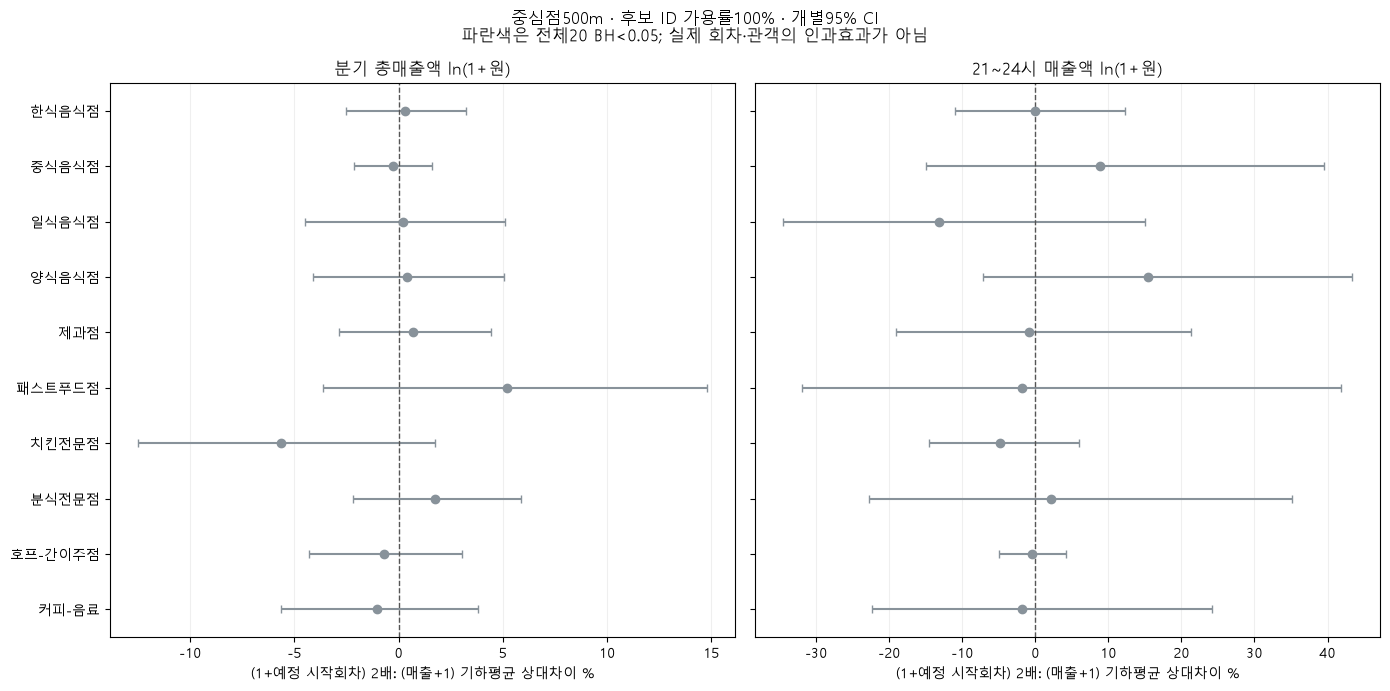

In [11]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
fonts={f.name for f in fm.fontManager.ttflist}
plt.rcParams['font.family']=next((x for x in ['Malgun Gothic','NanumGothic','AppleGothic'] if x in fonts),'DejaVu Sans')
plt.rcParams.update({'axes.unicode_minus':False,'font.size':10})
fig,axes=plt.subplots(1,2,figsize=(14,7),sharey=True)
for ax,outcome in zip(axes,OUTCOMES):
    part=primary.loc[primary.outcome.eq(outcome)].set_index('industry_id').reindex(INDUSTRY_IDS)
    for j,row in enumerate(part.itertuples()):
        if row.status!='estimated': ax.text(0,j,'미추정',va='center',color='#666666'); continue
        ax.errorbar(row.doubling_pct,j,xerr=[[row.doubling_pct-row.doubling_ci_low],[row.doubling_ci_high-row.doubling_pct]],fmt='o',capsize=3,color='#176B86' if row.p_bh20<.05 else '#88929A')
    ax.set_yticks(range(10),[INDUSTRIES[i] for i in INDUSTRY_IDS]); ax.set_ylim(9.5,-.5)
    ax.axvline(0,color='#555555',ls='--',lw=1); ax.grid(axis='x',alpha=.2)
    ax.set_title(OUTCOMES[outcome]); ax.set_xlabel('(1+예정 시작회차) 2배: (매출+1) 기하평균 상대차이 %')
fig.suptitle('중심점500m · 후보 ID 가용률100% · 개별95% CI\n파란색은 전체20 BH<0.05; 실제 회차·관객의 인과효과가 아님')
fig.tight_layout(); fig.savefig(R/'13_primary_effects.png',dpi=160,bbox_inches='tight')
plt.show(); plt.close(fig)

## 8. 해석 한계와 저장

예정회차는 관객량이 아니며 정상요일 반복·누락된 등록 자료·현행 좌표와 경계의 과거 적용 문제가 남는다. 중심점500m를 써도 매출은 상권 전체다. 100% 가용은 일정 정보가 완전한 선택표본이며, 공연이 밀집한 핵심 상권이 제외될 가능성이 있으므로 종로·마포 전체 공연경제로 일반화하지 않는다. 이 선택은 사전 지정90% 감도와 별도14번 표본감사에서 함께 검토한다.

군집·공간 SE는 교란이나 역인과를 제거하지 않는다. 비유의성은 효과 부재의 증거가 아니고 유의성은 실제 관객이 매출을 높였다는 증거가 아니다. 야간0↔양수 이동을 포함한 log(1+원) 결과이며 점포당 매출은 해석하지 않는다.

In [12]:
validation_table=pd.DataFrame(validation); assert validation_table.passed.all()
assert all(sha(ROOT/path)==value for path,value in protected.items())
assert all(sha(ROOT/path)==value for path,value in input_hashes.items())
outputs={'13_effects.csv':effects,'13_model_samples.csv':model_samples,'13_eligibility.csv':eligibility,'13_sample_membership.csv':member,
 '13_sample_flow.csv':sample_flow,'13_availability_support.csv':availability,'13_zero_night_diagnostics.csv':zero_night,'13_common10_support.csv':common10,
 '13_information_concentration.csv':information,'13_slope_covariances.csv':covariance_table,'13_exposure_comparison.csv':comparison,
 '13_spatial_se_sensitivity.csv':spatial_sensitivity,'13_implementation_checks.csv':validation_table,'13_multiplicity_counts.csv':counts,'13_prior_total_reference.csv':prior}
for name,f in outputs.items():
    assert name.startswith('13_'); f.to_csv(R/name,index=False,encoding='utf-8-sig')
lines=[]
for outcome in OUTCOMES:
    m=models[(PRIMARY,outcome)]; e=primary.loc[primary.outcome.eq(outcome)]
    lines.append(f"{OUTCOMES[outcome]}: 추정 {len(m['blocks'])}/10종, {m['nobs']:,}행·{m['clusters']}상권; 보정 전 {int(e.p_value.lt(.05).sum())}개, BH10 {int(e.p_bh10.lt(.05).sum())}개, 전체20 BH {int(e.p_bh20.lt(.05).sum())}개 유의.")
lines+=['같은 중심점·같은 후보 행의 예정회차/ID 비교이며 서로 다른 노출 단위의 기울기 크기를 직접 비교하지 않는다.',
        '공간 SE는 고정 kernel의 정규근사 참고구간이며 공간 p값이나 새 유의성 판정으로 사용하지 않는다.']
def finite(v):
    if isinstance(v,dict): return {k:finite(x) for k,x in v.items()}
    if isinstance(v,list): return [finite(x) for x in v]
    if isinstance(v,float) and not np.isfinite(v): return None
    return v
summary=finite(dict(status='complete',created_utc=datetime.now(timezone.utc).isoformat(),plan=PLAN,plan_sha256=plan_sha,input_sha256=input_hashes,
 protected_sha256=protected,all_inputs_unchanged=True,protected_unchanged=True,network_requests=0,causal_identification=False,implementation_checks_passed=len(validation),
 primary_results=primary.to_dict('records'),test_counts=counts.to_dict('records'),id_comparison_candidate_samples_identical=bool(comparison.identical_candidate_rows.all()),
 id_comparison_estimated_samples_identical=bool(comparison.identical_entire_estimated_sample.all()),conclusions=lines,python=platform.python_version(),
 output_sha256={name:sha(R/name) for name in [*outputs,'13_primary_effects.png']}))
(R/'13_analysis_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
display(Markdown('\n\n'.join(lines)))
print('저장 완료 / 고정 입력·기존 결과 해시 불변')

분기 총매출액 ln(1+원): 추정 10/10종, 5,015행·114상권; 보정 전 0개, BH10 0개, 전체20 BH 0개 유의.

21~24시 매출액 ln(1+원): 추정 10/10종, 5,015행·114상권; 보정 전 0개, BH10 0개, 전체20 BH 0개 유의.

같은 중심점·같은 후보 행의 예정회차/ID 비교이며 서로 다른 노출 단위의 기울기 크기를 직접 비교하지 않는다.

공간 SE는 고정 kernel의 정규근사 참고구간이며 공간 p값이나 새 유의성 판정으로 사용하지 않는다.

저장 완료 / 고정 입력·기존 결과 해시 불변
